# IS 362 — Mushroom Data Preprocessing
This notebook uses the [UCI Mushroom dataset](https://archive.ics.uci.edu/dataset/73/mushroom). We examine whether odor and bruising help predict whether a mushroom is edible or poisonous.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"
columns = ["class", "cap_shape", "cap_surface", "cap_color", "bruises", "odor"]
# The original file has 23 columns; select positions 0, 4, and 5.
df = pd.read_csv(url, header=None, usecols=[0, 4, 5])
df.columns = ["class", "bruises", "odor"]
print(df.head())

  class bruises odor
0     p       t    p
1     e       t    a
2     e       t    l
3     p       t    p
4     e       f    n


## Data dictionary
Class: `e` = edible, `p` = poisonous. Bruises: `t` = bruises, `f` = no bruises. Odor: `a` = almond, `l` = anise, `c` = creosote, `y` = fishy, `f` = foul, `m` = musty, `n` = none, `p` = pungent, `s` = spicy. These codes are from the UCI dataset description.

In [2]:
class_codes = {"e": 0, "p": 1}
bruises_codes = {"f": 0, "t": 1}
odor_codes = {"a": 0, "l": 1, "c": 2, "y": 3, "f": 4, "m": 5, "n": 6, "p": 7, "s": 8}
df["class"] = df["class"].map(class_codes)
df["bruises"] = df["bruises"].map(bruises_codes)
df["odor"] = df["odor"].map(odor_codes)
print(df.head())

   class  bruises  odor
0      1        1     7
1      0        1     0
2      0        1     1
3      1        1     7
4      0        0     6



class distribution:
class
0    4208
1    3916
Name: count, dtype: int64


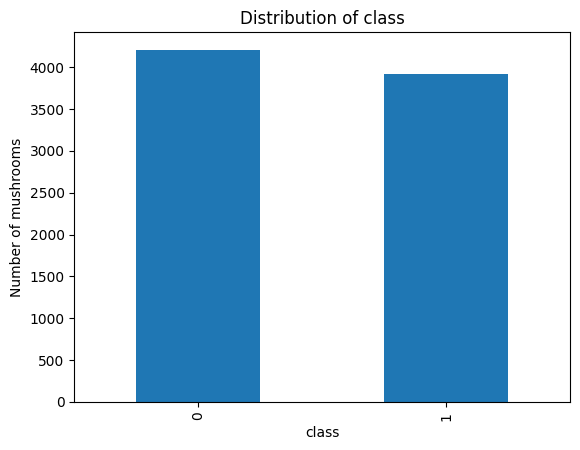


bruises distribution:
bruises
0    4748
1    3376
Name: count, dtype: int64


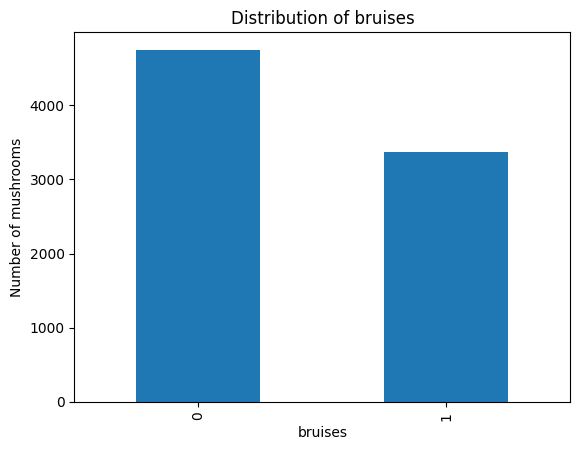


odor distribution:
odor
0     400
1     400
2     192
3     576
4    2160
5      36
6    3528
7     256
8     576
Name: count, dtype: int64


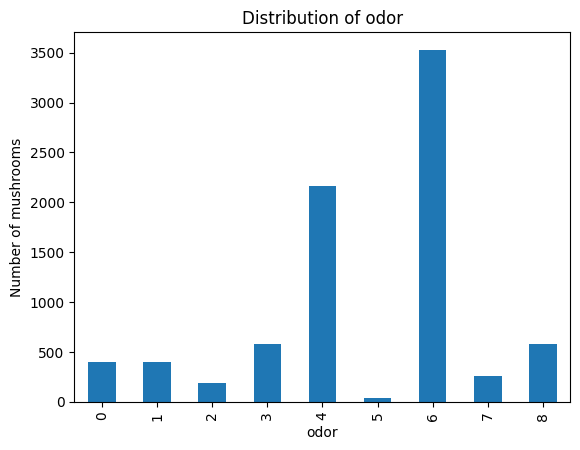

In [3]:
for column in df.columns:
    print(f"\n{column} distribution:\n{df[column].value_counts().sort_index()}")
    df[column].value_counts().sort_index().plot(kind="bar", title=f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of mushrooms")
    plt.show()

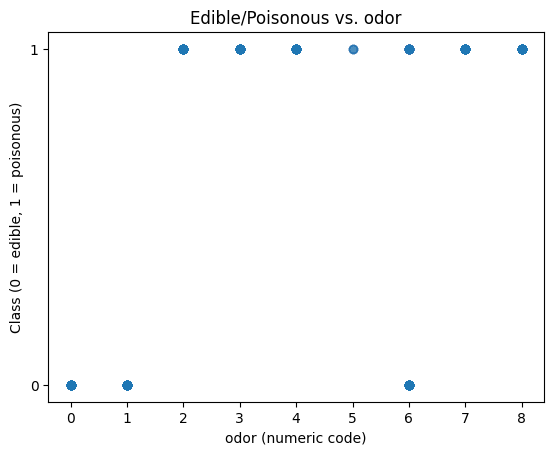

class     0     1
odor             
0      1.00  0.00
1      1.00  0.00
2      0.00  1.00
3      0.00  1.00
4      0.00  1.00
5      0.00  1.00
6      0.97  0.03
7      0.00  1.00
8      0.00  1.00


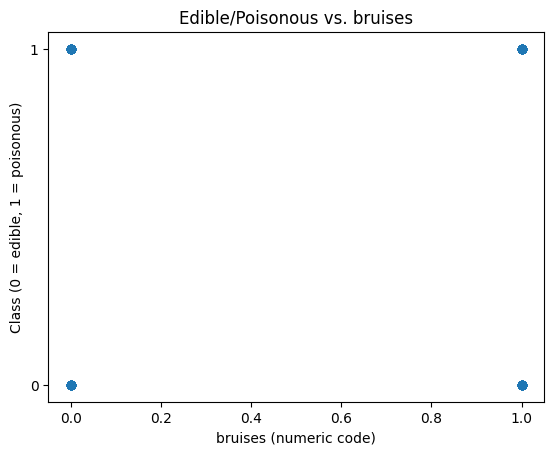

class       0     1
bruises            
0        0.31  0.69
1        0.82  0.18


In [4]:
for feature in ["odor", "bruises"]:
    plt.scatter(df[feature], df["class"], alpha=0.04)
    plt.xlabel(feature + " (numeric code)")
    plt.ylabel("Class (0 = edible, 1 = poisonous)")
    plt.title(f"Edible/Poisonous vs. {feature}")
    plt.yticks([0, 1])
    plt.show()
    print(pd.crosstab(df[feature], df["class"], normalize="index").round(2))

## Preliminary conclusions
Odor looks promising as a predictor because some odor categories are strongly associated with one class. Bruising may also help, but it is less precise because both edible and poisonous mushrooms can have the same bruising status. The cross-tabulations above help show these patterns more clearly than overlapping scatterplot points. Numeric odor codes are **category labels**, not a meaningful numerical scale; for Project 4, one-hot encoding may be preferable for models that interpret numbers as ordered values. These data are for classroom analysis only, not for deciding whether wild mushrooms are safe to eat.